# Quantifying Science Skepticism in the U.S. (GSS 2024 Analysis)

*Author: Eric Smith*  
*Date: September 2025*  

---

## 1. Introduction

Science skepticism shapes debates around **climate change, vaccines, and public trust in research**.  
The **General Social Survey (GSS)**, one of the most respected social surveys in the U.S., provides rich data to explore these attitudes.

**Research Question:**  
*What demographic, cultural, and institutional factors predict science skepticism in the U.S.?*

We will:
- Define two measures of skepticism from GSS 2024
- Explore correlations and categorical associations
- Build logistic regression models
- Interpret predictors using odds ratio* and a forest plot

---

## 2. Data Import and Setup


In [1]:
import os
import pandas as pd
import pyreadstat

# Load GSS 2024 data (SPSS format)
data_dir = "../input/gss2024"   # <-- Adjust for your Kaggle dataset path
file_path = os.path.join(data_dir, "GSS2024.sav")

df, meta = pyreadstat.read_sav(file_path)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()


Rows: 3309
Columns: 639


,abany,abanyg,abdefect,abdefectg,abhlth,abhlthg,abnomore,abnomoreg,abpoor,abpoorg,...,wrkstat,wrldgovt,wtssnrps,wtssps,xmarsex,xmovie,xmoviey,xnorcsiz,year,yousup
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,NaN,2.369490,1.889989,NaN,1.0,NaN,4.0,2024.0,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.0,3.0,1.391160,1.152265,NaN,NaN,4.0,4.0,2024.0,NaN
2,1.0,1.0,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,...,5.0,2.0,1.171199,0.915609,1.0,2.0,NaN,4.0,2024.0,NaN
3,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,...,2.0,NaN,2.735830,2.288064,1.0,NaN,NaN,4.0,2024.0,NaN
4,2.0,2.0,NaN,2.0,NaN,1.0,NaN,2.0,NaN,2.0,...,5.0,3.0,1.272915,1.005427,1.0,2.0,NaN,4.0,2024.0,NaN


We have ~3300 respondents and ~639 variables. GSS uses numeric codes with **value labels** (e.g., 1 = "a great deal", 2 = "only some", 3 = "hardly any"). We’ll construct variables for analysis.


## 3. Variable Construction

We focus on two indicators:

1. **Confidence in Science (`consci`)**  
   - 1 = A great deal  
   - 2 = Only some  
   - 3 = Hardly any: Treated as **science skepticism**

2. **Science Spending (`natsci`)**  
   - 1 = Too little  
   - 2 = About right  
   - 3 = Too much: Treated as **funding skepticism**


In [2]:
import numpy as np

df["sci_skeptic"] = np.where(df["consci"] == 3.0, 1, 0)
df.loc[df["consci"].isna(), "sci_skeptic"] = np.nan

df["fund_skeptic"] = np.where(df["natsci"] == 3.0, 1, 0)
df.loc[df["natsci"].isna(), "fund_skeptic"] = np.nan

df[["consci","sci_skeptic","natsci","fund_skeptic"]].head(10)


,consci,sci_skeptic,natsci,fund_skeptic
0,3.0,1.0,2.0,0.0
1,1.0,0.0,3.0,1.0
2,1.0,0.0,2.0,0.0
3,NaN,NaN,3.0,1.0
4,2.0,0.0,2.0,0.0
5,1.0,0.0,1.0,0.0
6,1.0,0.0,1.0,0.0
7,NaN,NaN,NaN,NaN
8,2.0,0.0,1.0,0.0
9,NaN,NaN,1.0,0.0


## 4. Exploratory Analysis (EDA)

We start with correlations (numeric predictors) and chi-square tests (categorical predictors).


In [3]:
# Correlations with sci_skeptic
corr_df = df.dropna(subset=["sci_skeptic"])
correlations = corr_df.corr(numeric_only=True)["sci_skeptic"].sort_values(ascending=False)

print("Top Positive Correlations:")
print(correlations.head(20))

print("\nTop Negative Correlations:")
print(correlations.tail(20))


Top Positive Correlations:
sci_skeptic     1.000000
consci          0.718850
nouseint1       0.509175
coevwork        0.461311
racecen3        0.332228
conmedic        0.300914
fund_skeptic    0.263188
conlabor        0.260526
divlawnv        0.252351
nouseint6       0.250000
confed          0.233473
abhlth          0.222448
prayer          0.217651
letinasn        0.208695
conarmy         0.208169
immideas1       0.207262
immameco        0.207070
immfate         0.203593
natsci          0.203481
corruptn        0.201303
Name: sci_skeptic, dtype: float64

Top Negative Correlations:
rateincumbts   -0.201883
ratechall2ts   -0.202634
ratechall224   -0.202634
numemps        -0.210816
ratedemp       -0.215412
immjobs        -0.219874
immcrime       -0.235739
nouseint7      -0.288675
nouseint12     -0.509175
nouseint4      -0.509175
ftruse         -0.553294
nouseint11     -0.670820
nouseint9      -0.670820
acqntsex             NaN
cohrs2               NaN
condom               NaN
crack30    

### Key Early Patterns:
- **Digital divide**: non-use of the internet strongly predicts skepticism.
- **Institutional distrust**: low confidence in medicine, government, unions points to higher skepticism.
- **Cultural attitudes**: immigration restrictions and religiosity correlate with skepticism.


In [4]:
# Chi-square tests for categorical predictors
import scipy.stats as stats

chi_results = []
for col in df.columns:
    if col not in ["sci_skeptic","fund_skeptic"]:
        cross = pd.crosstab(df["sci_skeptic"], df[col])
        if cross.shape[0] > 1 and cross.shape[1] > 1:
            try:
                chi2, p, dof, ex = stats.chi2_contingency(cross.fillna(0))
                chi_results.append((col, p, chi2, dof))
            except:
                pass

chi_df = pd.DataFrame(chi_results, columns=["Variable","p_value","chi2","dof"])
chi_df.sort_values("p_value").head(20)


,Variable,p_value,chi2,dof
112,consci,0.000000e+00,2121.000000,2
109,conmedic,3.731717e-58,264.466134,2
369,natsci,1.217995e-31,142.365863,2
104,confed,3.160781e-28,126.643127,2
100,conarmy,1.689648e-26,118.685385,2
111,conpress,1.662087e-25,114.113106,2
103,coneduc,5.877193e-22,97.771586,2
108,conlegis,8.903485e-22,96.940859,2
107,conlabor,3.210248e-21,94.375877,2
241,immjobs,1.353676e-20,99.348594,4


## 5. Logistic Regression

We now model `sci_skeptic` using top predictors identified in the chi-square step.


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

predictors = [
    "conmedic","confed","conarmy","conpress","coneduc","conlegis","conlabor",
    "conbus","confinan","contv",
    "natsci","natenrgy","immjobs","immcrime",
    "polviews","econstat"
]

model_df = df[predictors + ["sci_skeptic"]].dropna()
X = model_df[predictors]
y = model_df["sci_skeptic"]

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

log_reg = LogisticRegression(max_iter=2000, solver="lbfgs")
log_reg.fit(X_train, y_train)

print("Accuracy (test):", log_reg.score(X_test, y_test))
print("\nClassification report:")
print(classification_report(y_test, log_reg.predict(X_test)))


Accuracy (test): 0.9173553719008265

Classification report:
              precision    recall  f1-score   support

         0.0       0.92      0.99      0.96       108
         1.0       0.80      0.31      0.44        13

    accuracy                           0.92       121
   macro avg       0.86      0.65      0.70       121
weighted avg       0.91      0.92      0.90       121



## 6. Odds Ratios and Forest Plot

Raw coefficients are hard to interpret. Using statsmodels, we calculate **odds ratios** and visualize them.


In [6]:
import statsmodels.api as sm

X_sm = sm.add_constant(X_train)
logit_model = sm.Logit(y_train, X_sm).fit()
params = logit_model.params
conf = logit_model.conf_int()

or_table = pd.DataFrame({
    "Variable": params.index,
    "OddsRatio": np.exp(params),
    "CI Lower": np.exp(conf[0]),
    "CI Upper": np.exp(conf[1]),
    "p-value": logit_model.pvalues
}).sort_values("OddsRatio", ascending=False)

or_table


Optimization terminated successfully.
         Current function value: 0.206381
         Iterations 9


,Variable,OddsRatio,CI Lower,CI Upper,p-value
confinan,confinan,2.901437,1.275216e+00,6.601500,0.011099
confed,confed,2.600446,8.002507e-01,8.450251,0.111975
natsci,natsci,2.290158,1.124789e+00,4.662940,0.022365
conbus,conbus,2.082961,9.372102e-01,4.629404,0.071731
conarmy,conarmy,2.026196,9.708710e-01,4.228645,0.059943
conmedic,conmedic,1.568479,7.307730e-01,3.366472,0.248063
contv,contv,1.524626,5.459977e-01,4.257316,0.420838
natenrgy,natenrgy,1.487260,7.796778e-01,2.836995,0.228336
conpress,conpress,1.438497,3.750700e-01,5.517032,0.596013
polviews,polviews,1.181887,8.080466e-01,1.728683,0.389035


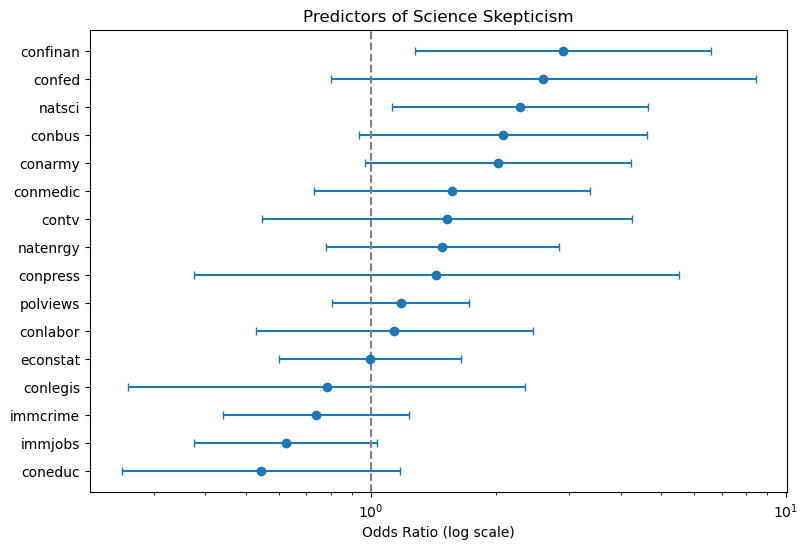

In [8]:
import matplotlib.pyplot as plt

# Forest plot
plot_df = or_table[or_table["Variable"].str.lower().ne("const")].sort_values("OddsRatio")

fig, ax = plt.subplots(figsize=(9,6))
ypos = np.arange(len(plot_df))
ax.errorbar(
    x=plot_df["OddsRatio"], y=ypos,
    xerr=[plot_df["OddsRatio"]-plot_df["CI Lower"], plot_df["CI Upper"]-plot_df["OddsRatio"]],
    fmt='o', capsize=3
)
ax.axvline(1, color="gray", linestyle="--")
ax.set_yticks(ypos)
ax.set_yticklabels(plot_df["Variable"])
ax.set_xscale("log")
ax.set_xlabel("Odds Ratio (log scale)")
ax.set_title("Predictors of Science Skepticism")
plt.show()


## 7. Discussion

- **Institutional Distrust:** People who are skeptical of finance, government, or business are also much more likely to be skeptical of science. 
- **Policy Views:** Thinking that the U.S. spends “too much” on science is one of the clearest markers of skepticism. 
- **Counterweights:** Trust in education and more positive views of immigration go hand-in-hand with lower levels of skepticism.
- **Cultural Alignment:** Conservatism nudges skepticism upward, but overall it plays a smaller role than institutional trust.

---

## 8. Conclusion

Science skepticism in the 2024 GSS doesn’t stand alone — it fits into a larger pattern of distrust.
Views about funding, education, and immigration help explain who is more or less skeptical.

This analysis shows how classic survey data, when combined with a bit of Python, can give a clear picture of the social forces behind public attitudes toward science.

These results show associations within the 2024 GSS dataset. Because we dropped missing values and did not apply survey weights, the findings should not be taken as exact population estimates — but they do highlight patterns worth further investigation.


## Data Source and Citation

This analysis uses data from the **General Social Survey (GSS) 2024**.  
The dataset is not redistributed here in compliance with NORC’s copyright and licensing.  
You can download it directly from NORC’s official GSS Data Explorer:

🔗 [https://gssdataexplorer.norc.org/gss_data](https://gssdataexplorer.norc.org/gss_data)

**Citation (Academic Use):**  
Davern, Michael; Bautista, Rene; Freese, Jeremy; Herd, Pamela; and Morgan, Stephen L.  
*General Social Survey 1972–2024. [Machine-readable data file].* NORC ed. Chicago, 2025.  

**Acknowledgment:**  
The General Social Survey (GSS) is a project of the independent research organization NORC at the University of Chicago, with principal funding from the National Science Foundation.
